<a href="https://colab.research.google.com/github/srochat/PolymerWork/blob/main/Copy_of_bert.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import time
import random
import requests
from bs4 import BeautifulSoup
import pandas as pd
from urllib.parse import urljoin
from tqdm import tqdm  # 进度条库

# 初始化设置
DOWNLOAD_DIR = os.path.join(os.getcwd(), "polymer_papers_4")
os.makedirs(DOWNLOAD_DIR, exist_ok=True)

# 用户代理和关键词配置
USER_AGENTS = [
    "Mozilla/5.0 (Windows NT 10.0; Win64; x64)",
    "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7)",
    "Mozilla/5.0 (Linux; Android 10; SM-A205U)"
]
KEYWORDS = [
    #"conductive polymer"
    #"polymer ",
    #"polymer constructure",
    #"polymer useage"
    #"polymer synthesis",
    #"polymer characterization",
    #"polymer composites",
    #"polymer degradation",
    #"polymer rheology",
    #"polymer nanoparticles",
    #"polymer blends",
    #"polymer membranes",
    #"polymer recycling",
    "Biodegradable polymers",
    "Polymer crystallinity",
    "Polymer electrolytes",
    "Polymerization mechanisms",
    "Controlled radical polymerization",
    "Ring-opening polymerization",
    "Step-growth polymerization",
    "Living polymerization",
    "Polymer morphology",
    "Glass transition temperature",
    "Polymer crystallinity",
    "Mechanical properties of polymers",
    "Thermal stability of polymers",
    "Stimuli-responsive polymers",
    "Self-healing polymers",
    "Supramolecular polymers",
    "Polymer gels",
    "Ionic polymers",
    "Polymer coatings",
    "Polymer adhesives",
    "Polymer biomaterials",
    "Polymer sensors",
    "Polymer-based drug delivery",
    "Biobased polymers",
    "Polymer upcycling",
    "Microplastics degradation",
    "Polymer waste management"
]
MAX_PAPERS_PER_KEYWORD = 30  # 每个关键词抓取50篇
REQUEST_DELAY = 1.5  # 请求间隔(秒)

def get_random_agent():
    return random.choice(USER_AGENTS)

def sanitize_filename(title):
    """生成安全的文件名"""
    keep_chars = (' ', '.', '_')
    return "".join(c for c in title if c.isalnum() or c in keep_chars).strip()[:50]

def search_papers(keyword, max_papers):
    """搜索论文并返回去重后的列表"""
    print(f"\n🔍 正在搜索: {keyword}")
    base_urls = [
        "https://arxiv.org/search/?query=",
        "https://www.ncbi.nlm.nih.gov/pmc/?term=",
        "https://www.sciencedirect.com/search?qs="
    ]

    papers = []
    seen_urls = set()

    for url_base in base_urls:
        try:
            url = url_base + keyword.replace(" ", "+")
            response = requests.get(url, headers={"User-Agent": get_random_agent()}, timeout=15)
            soup = BeautifulSoup(response.text, 'html.parser')

            # arXiv解析
            if "arxiv.org" in url:
                for item in soup.select(".arxiv-result"):
                    if len(papers) >= max_papers:
                        break
                    url = urljoin("https://arxiv.org", item.a["href"].replace("abs", "html"))
                    if url not in seen_urls:
                        papers.append({
                            "title": item.select_one(".title").text.strip(),
                            "url": url,
                            "source": "arXiv"
                        })
                        seen_urls.add(url)

            # PMC解析
            elif "ncbi.nlm.nih.gov" in url:
                for item in soup.select(".rprt"):
                    if len(papers) >= max_papers:
                        break
                    url = urljoin("https://www.ncbi.nlm.nih.gov", item.a["href"]) + "?report=reader"
                    if url not in seen_urls:
                        papers.append({
                            "title": item.select_one(".title").text.strip(),
                            "url": url,
                            "source": "PMC"
                        })
                        seen_urls.add(url)

            time.sleep(REQUEST_DELAY)

        except Exception as e:
            print(f"⚠️ 搜索失败 {url_base}: {str(e)}")

    return papers

def download_html(papers):
    """下载并保存HTML"""
    success_count = 0
    existing_files = set(os.listdir(DOWNLOAD_DIR))

    for paper in tqdm(papers, desc="下载进度"):
        try:
            # 生成唯一文件名
            safe_title = sanitize_filename(paper['title'])
            filename = f"{safe_title}_{paper['source']}.html"
            filepath = os.path.join(DOWNLOAD_DIR, filename)

            # 跳过已下载文件
            if filename in existing_files:
                continue

            # 下载内容
            for attempt in range(3):
                try:
                    response = requests.get(
                        paper["url"],
                        headers={"User-Agent": get_random_agent()},
                        timeout=20
                    )
                    response.raise_for_status()

                    # 检查是否为付费墙
                    if "access denied" in response.text.lower():
                        raise ValueError("付费墙限制")

                    break
                except Exception as e:
                    if attempt == 2:
                        raise
                    time.sleep(3 * (attempt + 1))

            # 保存文件
            with open(filepath, "w", encoding='utf-8') as f:
                f.write(response.text)
            success_count += 1
            time.sleep(REQUEST_DELAY)

        except Exception as e:
            tqdm.write(f"❌ 失败: {paper['title'][:50]}... | 错误: {str(e)}")

    return success_count

if __name__ == "__main__":
    # 安装必要库（若未安装）
    try:
        from tqdm import tqdm
    except ImportError:
        print("正在安装tqdm...")
        import subprocess
        subprocess.run(["pip", "install", "tqdm"], check=True)
        from tqdm import tqdm

    # 主执行流程
    all_papers = []
    for keyword in KEYWORDS:
        papers = search_papers(keyword, MAX_PAPERS_PER_KEYWORD)
        all_papers.extend(papers)
        print(f"找到 {len(papers)} 篇 '{keyword}' 相关论文")
        time.sleep(2)

    # 保存总清单
    df = pd.DataFrame(all_papers)
    df.to_csv(os.path.join(DOWNLOAD_DIR, "all_papers_list4.csv"), index=False)
    print(f"\n📄 共找到 {len(df)} 篇论文，清单已保存")

    # 开始下载
    print("\n⏳ 开始批量下载（按Ctrl+C可中断）...")
    success = download_html(all_papers)
    print(f"\n🎉 完成！成功下载 {success}/{len(all_papers)} 篇论文")
    print(f"文件保存位置: {os.path.abspath(DOWNLOAD_DIR)}")

🎯 使用GPU: Tesla T4
=== Start the text classification task ===
successfully read 4999 data

=== Label distribution ===
physical_properties: 1024 条数据 (20.5%)
Morphological_properties: 1008 条数据 (20.2%)
intake_properties: 806 条数据 (16.1%)
thermal_properties: 1198 条数据 (24.0%)
0: 963 条数据 (19.3%)


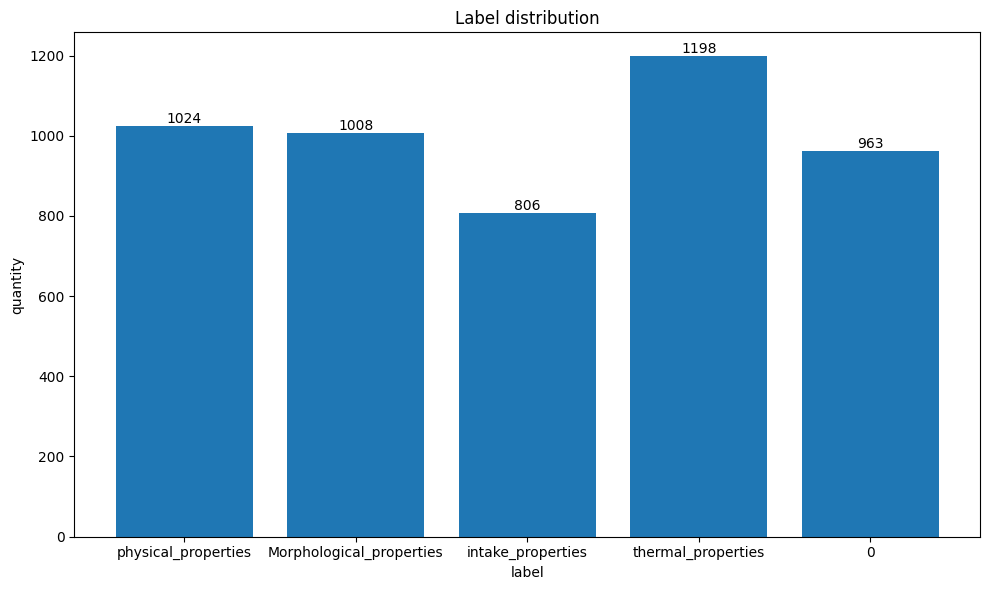

标签映射:lable_to_id {'thermal_properties': 0, 'intake_properties': 1, 'Morphological_properties': 2, '0': 3, 'physical_properties': 4}

输入数据形状: torch.Size([4999, 128])
Training set size: 3999
Test set size: 1000

=== load BERT model (type quantity: 5) ===


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


use the device: cuda

=== start training ===
Epoch 1, Batch 0, Loss: 1.6582
Epoch 1, Batch 50, Loss: 1.1692
Epoch 1, Batch 100, Loss: 0.7142
Epoch 1, Batch 150, Loss: 0.9874
Epoch 1, Batch 200, Loss: 0.6824
Epoch 1/3 - Average Loss: 0.8309, Train Accuracy: 0.6474
Epoch 2, Batch 0, Loss: 0.3226
Epoch 2, Batch 50, Loss: 0.6463
Epoch 2, Batch 100, Loss: 0.1578
Epoch 2, Batch 150, Loss: 0.1544
Epoch 2, Batch 200, Loss: 0.0736
Epoch 2/3 - Average Loss: 0.3479, Train Accuracy: 0.8810
Epoch 3, Batch 0, Loss: 0.3835
Epoch 3, Batch 50, Loss: 0.3091
Epoch 3, Batch 100, Loss: 0.2545
Epoch 3, Batch 150, Loss: 0.1459
Epoch 3, Batch 200, Loss: 0.0860
Epoch 3/3 - Average Loss: 0.2215, Train Accuracy: 0.9352

=== Draw a training process curve ===


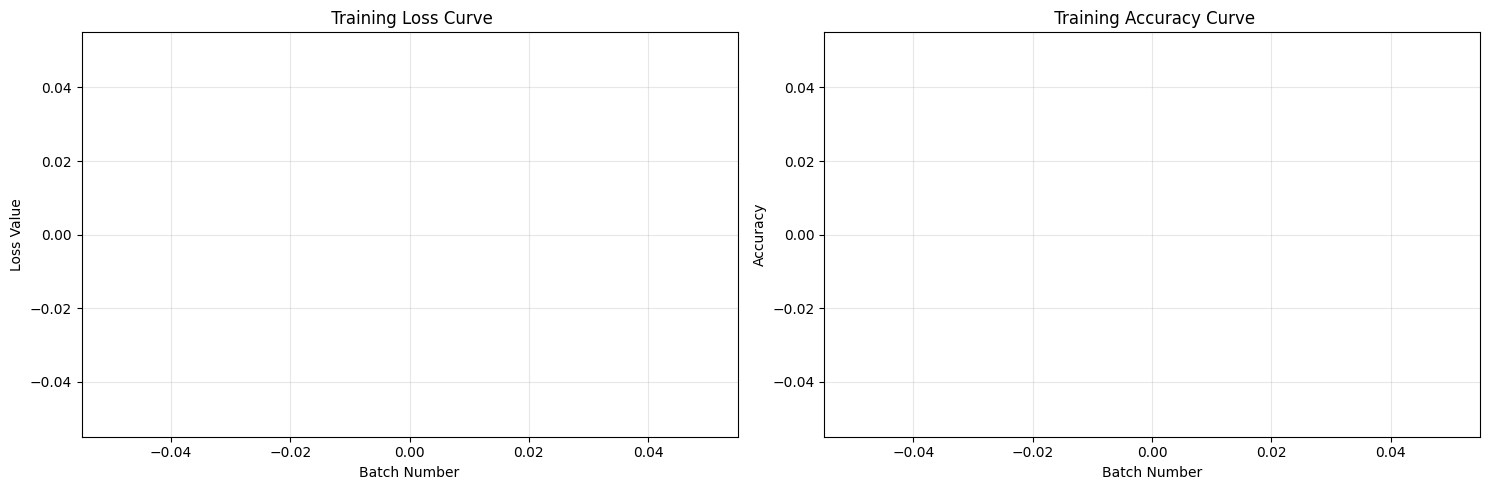

<Figure size 1000x500 with 0 Axes>

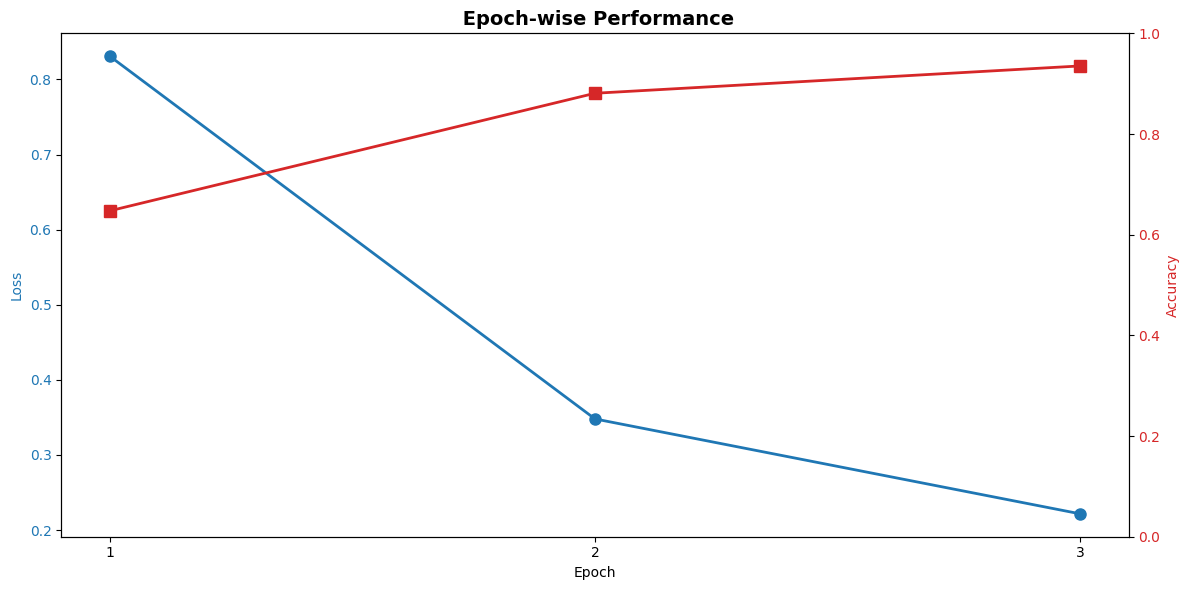


=== start evaluating ===
Test set accuracy: 0.9230

=== classification report ===
              precision    recall  f1-score   support

           0       0.97      0.98      0.97       222
           1       1.00      0.99      1.00       168
           2       0.92      0.81      0.86       200
           3       0.85      0.92      0.88       191
           4       0.90      0.91      0.90       219

    accuracy                           0.92      1000
   macro avg       0.93      0.92      0.92      1000
weighted avg       0.92      0.92      0.92      1000


=== Drawing performance visualization ===


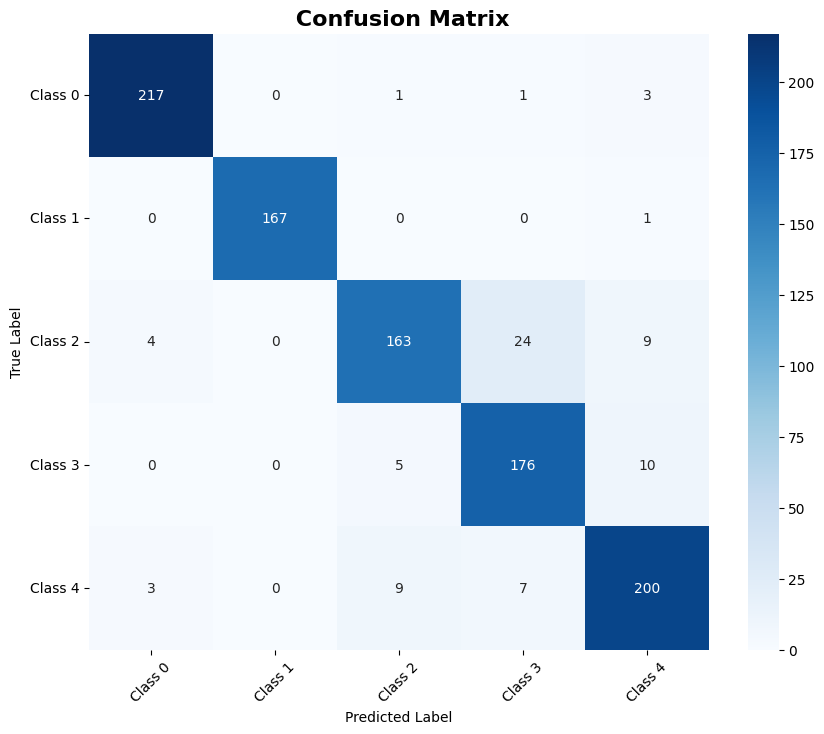

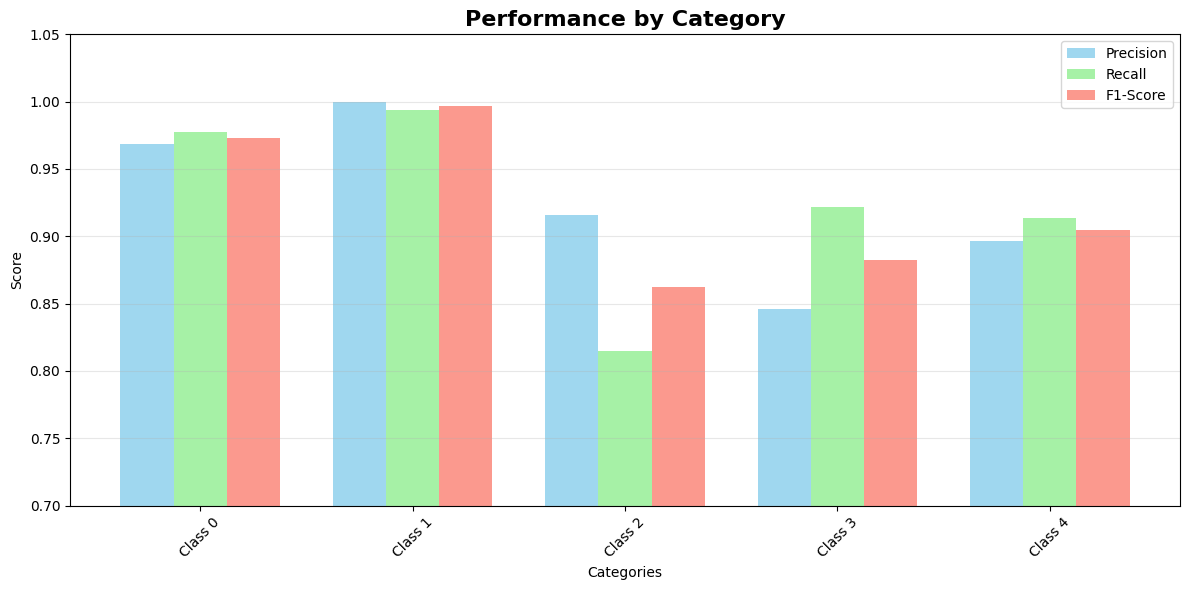


=== save model ===
the model has saved to  ./my_bert_model 

=== Finish! ===


In [ ]:
import torch
import pandas as pd
import numpy as np
from transformers import BertTokenizer, BertForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader, RandomSampler
from sklearn.metrics import accuracy_score, classification_report
from torch.optim import AdamW
import collections
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# ==================== 强制使用GPU的代码 ====================
#Force the use of GPU code
# Check and set up the device
if torch.cuda.is_available():
    device = torch.device("cuda")
    print(f"🎯 使用GPU: {torch.cuda.get_device_name(0)}")
else:
    device = torch.device("cpu")
    print("⚠️  CUDA不可用，使用CPU")

# Setting a random seed ensures reproducibility
torch.manual_seed(42)
if device.type == 'cuda':
    torch.cuda.manual_seed_all(42)

# The initialization list is used to store training process data
all_losses = []  # Store the loss of each batch
all_accuracies = []  # Store the accuracy of each batch
epoch_losses = []  # Store the average loss of each epoch
epoch_accuracies = []  # Store the accuracy of each epoch


# 1. Data reading function
def read_csv_data(file_path):
    try:
        data = pd.read_csv(file_path, encoding='utf-8')
    except UnicodeDecodeError:
        try:
            data = pd.read_csv(file_path, encoding='gbk')
        except UnicodeDecodeError:
            try:
                data = pd.read_csv(file_path, encoding='gb2312')
            except:
                data = pd.read_csv(file_path, encoding='latin-1')

    texts = data['text'].tolist()
    labels = data['lable'].tolist()
    return texts, labels

# 2. data transfer function
def convert_data_to_bert_format(texts, labels):
    # use english BERT
    tokenizer = BertTokenizer.from_pretrained('bert-base-cased')

    encoded_dict = tokenizer.batch_encode_plus(
        texts,
        add_special_tokens=True,
        max_length=128,
        padding='max_length',
        truncation=True,
        return_attention_mask=True,
        return_tensors='pt'
    )

    input_ids = encoded_dict['input_ids']
    attention_masks = encoded_dict['attention_mask']

    # label processing
    if isinstance(labels[0], (int, float)):
        numeric_labels = labels
    else:
        unique_labels = list(set(labels))
        label_to_id = {label: idx for idx, label in enumerate(unique_labels)}
        print(f"标签映射:lable_to_id {label_to_id}")
        numeric_labels = [label_to_id[label] for label in labels]

    labels_tensor = torch.tensor(numeric_labels)

    return input_ids, attention_masks, labels_tensor, tokenizer

#Draw statistical graphs

# 3. Visualization function
def plot_training_curves():
    """绘制训练损失和准确率曲线"""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

    # 绘制损失曲线training loss curve
    ax1.plot(all_losses, alpha=0.7, linewidth=1)
    ax1.set_title(' Training Loss Curve')
    ax1.set_xlabel('Batch Number')
    ax1.set_ylabel('Loss Value')
    ax1.grid(True, alpha=0.3)

    # 绘制准确率曲线ttaining accuracy curve
    ax2.plot(all_accuracies, alpha=0.7, linewidth=1, color='orange')
    ax2.set_title(' Training Accuracy Curve')
    ax2.set_xlabel('Batch Number')
    ax2.set_ylabel('Accuracy')
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

def plot_epoch_performance():
    """绘制每个epoch的性能"""
    plt.figure(figsize=(10, 5))

    x = range(1, len(epoch_losses) + 1)
    width = 0.35

    fig, ax1 = plt.subplots(figsize=(12, 6))

    color = 'tab:blue'
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss', color=color)
    ax1.plot(x, epoch_losses, 'o-', color=color, label='Loss', linewidth=2, markersize=8)
    ax1.tick_params(axis='y', labelcolor=color)
    ax1.set_xticks(x)

    ax2 = ax1.twinx()
    color = 'tab:red'
    ax2.set_ylabel('Accuracy', color=color)
    ax2.plot(x, epoch_accuracies, 's-', color=color, label='Accuracy', linewidth=2, markersize=8)
    ax2.tick_params(axis='y', labelcolor=color)
    ax2.set_ylim(0, 1.0)

    plt.title(' Epoch-wise Performance', fontsize=14, fontweight='bold')
    fig.tight_layout()
    plt.show()

def plot_confusion_matrix(true_labels, predictions, class_names):
    """绘制混淆矩阵"""
    cm = confusion_matrix(true_labels, predictions)

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names,
                yticklabels=class_names)
    plt.title(' Confusion Matrix', fontsize=16, fontweight='bold')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    plt.show()

def plot_class_performance_report(true_labels, predictions, class_names):
    """绘制各类别性能对比图"""
    report = classification_report(true_labels, predictions, output_dict=True)

    precision = [report[str(i)]['precision'] for i in range(len(class_names))]
    recall = [report[str(i)]['recall'] for i in range(len(class_names))]
    f1_scores = [report[str(i)]['f1-score'] for i in range(len(class_names))]

    x = np.arange(len(class_names))
    width = 0.25

    plt.figure(figsize=(12, 6))
    plt.bar(x - width, precision, width, label='Precision', alpha=0.8, color='skyblue')
    plt.bar(x, recall, width, label='Recall', alpha=0.8, color='lightgreen')
    plt.bar(x + width, f1_scores, width, label='F1-Score', alpha=0.8, color='salmon')

    plt.title('Performance by Category', fontsize=16, fontweight='bold')
    plt.xlabel('Categories')
    plt.ylabel('Score')
    plt.xticks(x, class_names, rotation=45)
    plt.legend()
    plt.grid(True, alpha=0.3, axis='y')
    plt.ylim(0.7, 1.05)
    plt.tight_layout()
    plt.show()


# main program
print("=== Start the text classification task ===")

# read data
file_path = '/content/example.csv'
texts, labels = read_csv_data(file_path)

print(f"successfully read {len(texts)} data")
#print("first 3 text:", texts[:3])
#print("first 3 label:", labels[:3])

# View label distribution
label_counts = collections.Counter(labels)
print("\n=== Label distribution ===")
for label, count in label_counts.items():
    print(f"{label}: {count} 条数据 ({count/len(labels)*100:.1f}%)")

# create bar chart
plt.figure(figsize=(10, 6))
bars = plt.bar(range(len(label_counts)), label_counts.values())
plt.title('Label distribution')
plt.xlabel('label')
plt.ylabel('quantity')
plt.xticks(range(len(label_counts)), label_counts.keys())

# add number
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

# data transfer
input_ids, attention_masks, labels_tensor, tokenizer = convert_data_to_bert_format(texts, labels)
print(f"\n输入数据形状: {input_ids.shape}")

# data divide
train_inputs, test_inputs, train_masks, test_masks, train_labels, test_labels = train_test_split(
    input_ids, attention_masks, labels_tensor, test_size=0.2, random_state=42)

print(f"Training set size: {len(train_inputs)}")
print(f"Test set size: {len(test_inputs)}")

# Creating a Data Loader
batch_size = 16
train_dataset = TensorDataset(train_inputs, train_masks, train_labels)
test_dataset = TensorDataset(test_inputs, test_masks, test_labels)

train_dataloader = DataLoader(train_dataset, sampler=RandomSampler(train_dataset), batch_size=batch_size)
test_dataloader = DataLoader(test_dataset, sampler=RandomSampler(test_dataset), batch_size=batch_size)

# load model
num_labels = len(torch.unique(labels_tensor))
print(f"\n=== load BERT model (type quantity: {num_labels}) ===")

model = BertForSequenceClassification.from_pretrained(
    'bert-base-uncased',
    num_labels=num_labels
)

# set up the device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"use the device: {device}")
model.to(device)

# set up the optimizer
optimizer = AdamW(model.parameters(), lr=3e-5, eps=1e-8)

# train model
print("\n=== start training ===")
epochs = 3

for epoch in range(epochs):
    model.train()
    total_loss = 0
    total_correct = 0
    total_samples = 0

    for step, batch in enumerate(train_dataloader):
        b_input_ids, b_attention_mask, b_labels = [t.to(device) for t in batch]

        model.zero_grad()

        outputs = model(b_input_ids,
                      attention_mask=b_attention_mask,
                      labels=b_labels)
        loss = outputs.loss
        logits = outputs.logits

        # Calculating accuracy
        preds = torch.argmax(logits, dim=1)
        correct = (preds == b_labels).sum().item()
        total_correct += correct
        total_samples += b_labels.size(0)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        total_loss += loss.item()

        # Print progress every 50 batches
        if step % 50 == 0:
            print(f"Epoch {epoch+1}, Batch {step}, Loss: {loss.item():.4f}")

    avg_loss = total_loss / len(train_dataloader)
    train_accuracy = total_correct / total_samples
    epoch_losses.append(avg_loss)
    epoch_accuracies.append(train_accuracy)
    print(f"Epoch {epoch+1}/{epochs} - Average Loss: {avg_loss:.4f}, Train Accuracy: {train_accuracy:.4f}")

# Draw a training process curve
print("\n=== Draw a training process curve ===")
plot_training_curves()
plot_epoch_performance()

# Evaluating the Model
print("\n=== start evaluating ===")
model.eval()
predictions, true_labels = [], []

for batch in test_dataloader:
    with torch.no_grad():
        b_input_ids, b_attention_mask, b_labels = [t.to(device) for t in batch]

        outputs = model(b_input_ids, attention_mask=b_attention_mask)
        logits = outputs.logits

        preds = torch.argmax(logits, dim=1).cpu().numpy()
        labels = b_labels.cpu().numpy()

        predictions.extend(preds)
        true_labels.extend(labels)

# Calculating evaluation metrics
accuracy = accuracy_score(true_labels, predictions)
print(f"Test set accuracy: {accuracy:.4f}")

print("\n=== classification report ===")
print(classification_report(true_labels, predictions))


# Plot confusion matrix and class performance graph
class_names = [f'Class {i}' for i in range(num_labels)]
print("\n=== Drawing performance visualization ===")
plot_confusion_matrix(true_labels, predictions, class_names)
plot_class_performance_report(true_labels, predictions, class_names)

# save model
print("\n=== save model ===")
model.save_pretrained('./my_bert_model')
tokenizer.save_pretrained('./my_bert_model')
print("the model has saved to  ./my_bert_model ")

print("\n=== Finish! ===")